# Path Reproduction — physical robot vs Digital Twin

Group project 04 *Path Reproduction* (Motors · odometry). One designed path with straights, a wide and a tight
arc, on-the-spot rotations in both directions, a reversal and four speed levels is run

* on the **real robot** — firmware `05_path_reproduction/Path_Reproduction/`, encoder closed loop, logs every 20 ms;
* in the **Digital Twin** — the supplied Processing twin extended in `05_path_reproduction/DigitalTwin_PathReproduction/`,
  and the same model in Python (`twin/twin.py`), both running **the same controller code** as the robot.

Two twin models are compared with the robot:

| model | motors | geometry | source |
|---|---|---|---|
| `course` | PWM → speed linear (PWM 200 = 0.25 mm/ms), wheels identical, no deadband, no lag | B = 90 mm, r = 16 mm | the supplied twin |
| `calibrated` | per-wheel gain above a deadband, first-order lag, right-wheel delay, integer PWM | B = 83.48 mm, r = 16.36 mm | fitted to this robot's Ex2–Ex4 logs |
| `refit_t6` | as `calibrated`, motor gains re-fitted on the real path run `path_t6` | B = 83.48 mm, r = 16.36 mm | the twin **updated** from the comparison (same run — needs a second run to validate) |

Questions: where and when do real and twin trajectories begin to diverge, which motion types produce the largest
differences, and which model assumptions explain them?

> Real runs are read from `data/real/path_t*.csv` (from `Path_Reproduction/wifi_logger.py`). Until they exist, the
> real-vs-twin cells say so and the notebook compares the two twins with each other.

In [1]:
import os, sys, glob, math, subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO_URL = "https://github.com/comradeofjustice/Bristol_odometry"
if os.path.isdir("05_path_reproduction"):
    BASE = "05_path_reproduction"
elif os.path.isdir("../twin"):
    BASE = ".."
else:
    if not os.path.isdir("Bristol_odometry"):
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    BASE = "Bristol_odometry/05_path_reproduction"
sys.path.insert(0, f"{BASE}/twin")
import twin, compare
print("project folder:", BASE)

project folder: 05_path_reproduction


## 1. The designed path

In [2]:
seg_table = []
for i, (seg, name, kind) in enumerate(zip(twin.PATH, twin.SEGMENT_NAMES, twin.SEGMENT_KIND), start=1):
    sl, sr = twin.wheel_distances(seg)
    seg_table.append({"segment": i, "name": name, "kind": kind, "max_pwm": seg[3],
                      "left_wheel_mm": round(sl, 1), "right_wheel_mm": round(sr, 1)})
seg_table = pd.DataFrame(seg_table)
nominal = twin.nominal_path()
print(f"designed path closes at ({nominal.x_mm.iloc[-1]:.2f}, {nominal.y_mm.iloc[-1]:.2f}) mm, "
      f"{math.degrees(nominal.theta_rad.iloc[-1]):.1f} deg")
seg_table

designed path closes at (-0.00, 0.00) mm, 360.0 deg


,segment,name,kind,max_pwm,left_wheel_mm,right_wheel_mm
0,1,straight 200 slow,straight,30.0,200.0,200.0
1,2,arc L R80 180,arc,35.0,120.2,382.5
2,3,straight 100 fast,straight,50.0,100.0,100.0
3,4,rotate CW 90,rotate,35.0,65.6,-65.6
4,5,reverse 100,reverse,35.0,-100.0,-100.0
5,6,rotate CCW 90,rotate,35.0,-65.6,65.6
6,7,straight 100,straight,40.0,100.0,100.0
7,8,arc L R60 90 (tight),arc,35.0,28.7,159.8
8,9,rotate CCW 90,rotate,35.0,-65.6,65.6
9,10,straight 60 slow,straight,30.0,60.0,60.0


## 2. Run both twins (Python) and check them against the Processing twin

In [3]:
runs = {name: twin.run(name) for name in twin.MODELS}
for name, df in runs.items():
    last = df.iloc[-1]
    print(f"{name:10s} {df.time_ms.iloc[-1]/1000:5.1f} s   true end ({last.x_true_mm:6.1f}, {last.y_true_mm:6.1f}) mm, "
          f"{math.degrees(last.theta_true_rad):6.1f} deg   robot odometry end ({last.x_mm:6.1f}, {last.y_mm:6.1f})")

# The Processing sketch writes twin_<model>_processing.csv on start-up; a copy is kept in data/twin/.
for name in twin.MODELS:
    path = f"{BASE}/data/twin/twin_{name}_processing.csv"
    if os.path.isfile(path):
        p = pd.read_csv(path)
        n = min(len(p), len(runs[name]))
        d = np.hypot(p.x_true_mm[:n] - runs[name].x_true_mm[:n], p.y_true_mm[:n] - runs[name].y_true_mm[:n])
        print(f"Processing vs Python ({name}): {len(p)} vs {len(runs[name])} rows, max position difference {d.max():.1f} mm")

course      35.3 s   true end (  -9.1,   67.2) mm,  325.1 deg   robot odometry end (  -1.5,    5.9)
calibrated  30.3 s   true end (   2.1,   -1.9) mm,  362.2 deg   robot odometry end (   2.2,   -1.7)
refit_t6    26.7 s   true end (   1.2,   -0.4) mm,  362.0 deg   robot odometry end (   1.3,   -0.3)
Processing vs Python (course): 1764 vs 1764 rows, max position difference 1.1 mm
Processing vs Python (calibrated): 1516 vs 1517 rows, max position difference 4.4 mm


## 3. Real robot runs

In [4]:
real_files = sorted(glob.glob(f"{BASE}/data/real/path_t*.csv"))
real = {os.path.basename(f)[:-4]: pd.read_csv(f) for f in real_files}
if real:
    for k, df in real.items():
        last = df.iloc[-1]
        print(f"{k}: {len(df)} rows, {df.time_ms.iloc[-1]/1000:.1f} s, segments {df.segment.max()}, "
              f"odometry end ({last.x_mm:.1f}, {last.y_mm:.1f}) mm, {math.degrees(last.theta_rad):.1f} deg")
else:
    print("No real runs yet: copy Path_Reproduction/logs/path_t*.csv into data/real/ and run again.")
    print("Until then the comparisons below use the calibrated twin as the reference and the course twin as the model.")
REF_NAME = ("real " + " + ".join(real)) if real else "calibrated twin"

path_t6: 1321 rows, 26.4 s, segments 11, odometry end (2.4, -0.5) mm, 361.9 deg


## 4. Trajectories

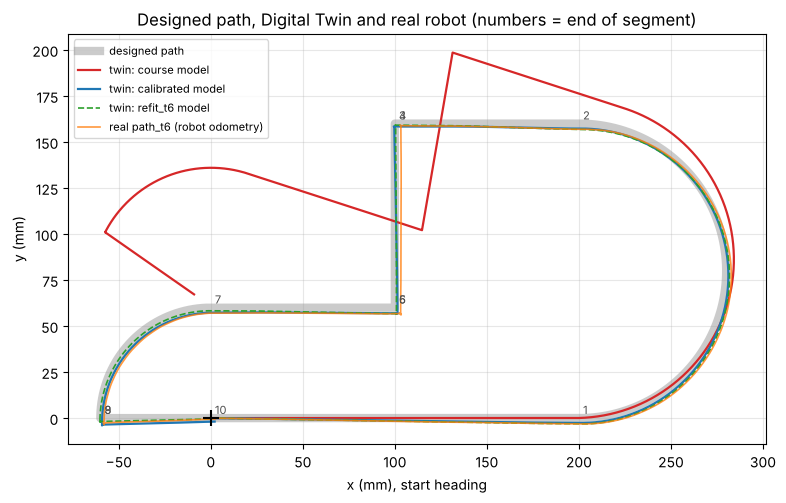

In [5]:
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(nominal.x_mm, nominal.y_mm, color="0.6", lw=6, alpha=0.5, label="designed path")
ax.plot(runs["course"].x_true_mm, runs["course"].y_true_mm, color="C3", lw=1.6, label="twin: course model")
ax.plot(runs["calibrated"].x_true_mm, runs["calibrated"].y_true_mm, color="C0", lw=1.6, label="twin: calibrated model")
ax.plot(runs["refit_t6"].x_true_mm, runs["refit_t6"].y_true_mm, color="C2", lw=1.2, ls="--", label="twin: refit_t6 model")
for k, df in real.items():
    ax.plot(df.x_mm, df.y_mm, color="C1", lw=1.2, alpha=0.8, label=f"real {k} (robot odometry)")
for i, row in nominal.groupby("segment").last().iterrows():
    if i >= 1:
        ax.annotate(str(i), (row.x_mm, row.y_mm), fontsize=8, color="0.3", xytext=(3, 3), textcoords="offset points")
ax.scatter([0], [0], marker="+", s=120, color="k", zorder=5)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="upper left")
ax.set_xlabel("x (mm), start heading"); ax.set_ylabel("y (mm)")
ax.set_title("Designed path, Digital Twin and real robot (numbers = end of segment)")
os.makedirs(f"{BASE}/analysis", exist_ok=True)
plt.savefig(f"{BASE}/analysis/trajectories.png", dpi=120, bbox_inches="tight")
plt.show()

## 5. Where and when do the trajectories diverge?

Two alignments: **by time** (same time since start — includes speed/timing differences) and **by progress**
(same fraction of each segment — isolates the geometry of the motion). Reference = real robot odometry when
available, otherwise the calibrated twin.

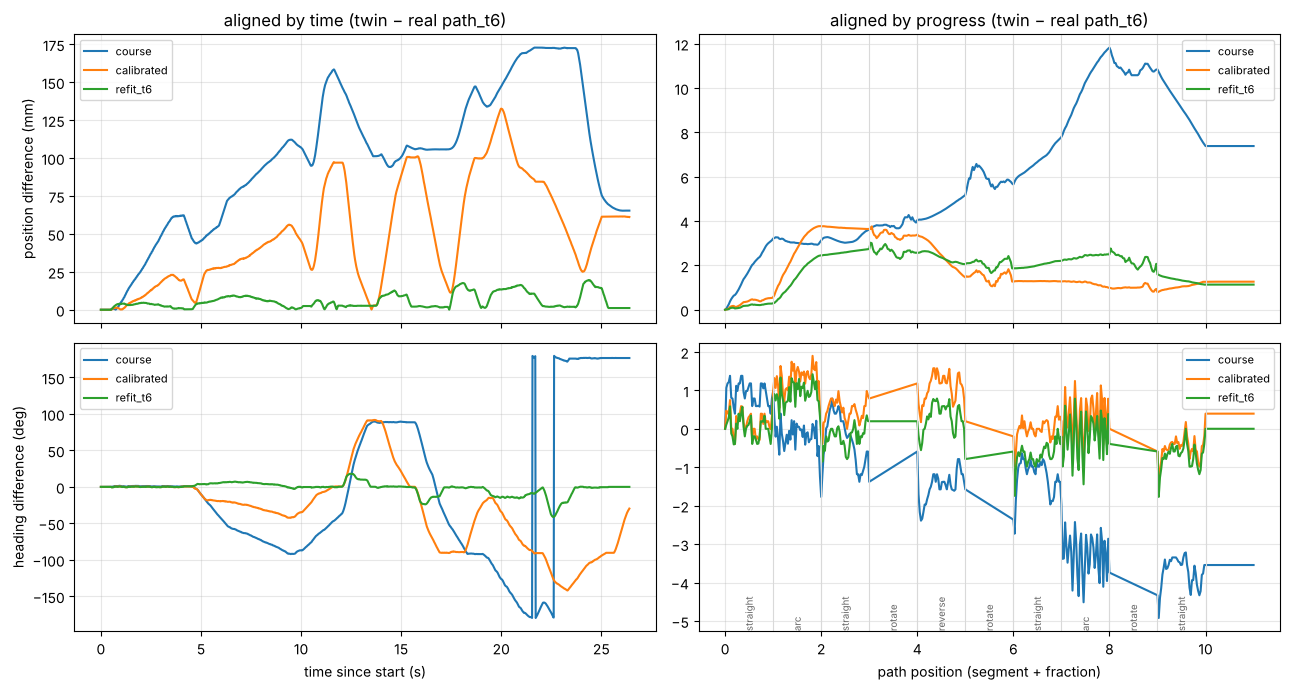

,model,total_time_s,reference_time_s,time_aligned_mean_dpos_mm,time_aligned_max_dpos_mm,progress_aligned_max_dpos_mm,progress_aligned_max_dheading_deg,onset_5mm_s
0,course,35.26,26.41,100.36,172.80,11.82,4.92,1.02
1,calibrated,30.32,26.41,49.89,132.56,3.77,1.90,1.54
2,refit_t6,26.73,26.41,5.70,19.54,3.03,1.77,5.34


In [6]:
cols_true = ("x_true_mm", "y_true_mm", "theta_true_rad")
cols_odo = ("x_mm", "y_mm", "theta_rad")
if real:
    ref = list(real.values())[0]; ref_cols = cols_odo; twin_cols = cols_odo   # like for like: odometry vs odometry
    models = {name: runs[name] for name in ("course", "calibrated", "refit_t6")}
else:
    ref = runs["calibrated"]; ref_cols = cols_true; twin_cols = cols_true
    models = {"course": runs["course"]}

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex="col")
onsets = {}
for name, df in models.items():
    at = compare.align_by_time(ref, df, ref_cols, twin_cols)
    ap = compare.align_by_progress(ref, df, ref_cols, twin_cols)
    onsets[name] = compare.divergence_onset(at)
    axes[0, 0].plot(at.time_ms / 1000, at.dpos_mm, label=name)
    axes[1, 0].plot(at.time_ms / 1000, at.dth_deg, label=name)
    axes[0, 1].plot(ap.s, ap.dpos_mm, label=name)
    axes[1, 1].plot(ap.s, ap.dth_deg, label=name)
for s in range(1, len(twin.PATH) + 1):
    for a in axes[:, 1]:
        a.axvline(s, color="0.85", lw=0.8)
for k, kind in enumerate(twin.SEGMENT_KIND):
    axes[1, 1].text(k + 0.5, axes[1, 1].get_ylim()[0], kind, rotation=90, fontsize=7, ha="center", va="bottom", color="0.4")
axes[0, 0].set_ylabel("position difference (mm)"); axes[1, 0].set_ylabel("heading difference (deg)")
axes[1, 0].set_xlabel("time since start (s)"); axes[1, 1].set_xlabel("path position (segment + fraction)")
axes[0, 0].set_title(f"aligned by time (twin − {REF_NAME})"); axes[0, 1].set_title(f"aligned by progress (twin − {REF_NAME})")
for a in axes.flat:
    a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{BASE}/analysis/divergence.png", dpi=120, bbox_inches="tight")
plt.show()
summary = []
for name, df in models.items():
    at = compare.align_by_time(ref, df, ref_cols, twin_cols)
    ap = compare.align_by_progress(ref, df, ref_cols, twin_cols)
    summary.append({"model": name, "total_time_s": df.time_ms.iloc[-1] / 1000,
                    "reference_time_s": ref.time_ms.iloc[-1] / 1000,
                    "time_aligned_mean_dpos_mm": at.dpos_mm.mean(), "time_aligned_max_dpos_mm": at.dpos_mm.max(),
                    "progress_aligned_max_dpos_mm": ap.dpos_mm.max(),
                    "progress_aligned_max_dheading_deg": ap.dth_deg.abs().max(),
                    "onset_5mm_s": (onsets[name]["position"] or {}).get("time_ms", np.nan) / 1000})
summary = pd.DataFrame(summary).round(2)
summary

## 6. Which motion types produce the largest differences?

Each segment's own motion, expressed in the frame where the segment started (so earlier errors do not count
again): forward and sideways displacement, rotation and duration. The difference twin − reference shows the
error **produced by that type of motion**.

In [7]:
ref_local = compare.segment_local_motion(ref, ref_cols)
if real and len(real) > 1:   # mean over all real runs
    ref_local = pd.concat([compare.segment_local_motion(df, cols_odo) for df in real.values()]).groupby("segment").mean().reset_index()
rows = []
for name, df in models.items():
    loc = compare.segment_local_motion(df, twin_cols)
    m = ref_local.merge(loc, on="segment", suffixes=("_ref", "_twin"))
    m = m[m.segment <= len(twin.PATH)]
    m["kind"] = [twin.SEGMENT_KIND[s - 1] for s in m.segment]
    m["model"] = name
    m["d_forward_mm"] = m.forward_mm_twin - m.forward_mm_ref
    m["d_left_mm"] = m.left_mm_twin - m.left_mm_ref
    m["d_rotation_deg"] = m.rotation_deg_twin - m.rotation_deg_ref
    m["duration_ratio"] = m.duration_ms_twin / m.duration_ms_ref
    rows.append(m)
per_segment = pd.concat(rows)
print(per_segment[["model", "segment", "kind", "d_forward_mm", "d_left_mm", "d_rotation_deg", "duration_ratio"]]
      .round(2).to_string(index=False))
by_kind = (per_segment.assign(abs_rot=per_segment.d_rotation_deg.abs(),
                              abs_pos=np.hypot(per_segment.d_forward_mm, per_segment.d_left_mm))
           .groupby(["model", "kind"])[["abs_pos", "abs_rot", "duration_ratio"]].mean().round(2))
by_kind.columns = ["mean |position error| per segment (mm)", "mean |rotation error| (deg)", "mean duration ratio"]
by_kind

     model  segment     kind  d_forward_mm  d_left_mm  d_rotation_deg  duration_ratio
    course        1 straight         -0.40       3.19            0.98            1.49
    course        2      arc          2.88      -0.12           -2.76            1.32
    course        3 straight         -0.54       2.59            0.39            1.86
    course        4   rotate         -0.76      -0.27            0.79            1.43
    course        5  reverse          0.99       1.61           -0.98            1.60
    course        6   rotate          0.66      -0.82           -0.79            1.41
    course        7 straight         -0.27       1.96            0.39            1.77
    course        8      arc          1.23      -1.34           -1.77            1.16
    course        9   rotate          1.01       0.07           -0.59            1.43
    course       10 straight         -0.29       0.64            0.79            1.31
calibrated        1 straight          0.16       0.55 

mean |position error| per segment (mm)  mean |rotation error| (deg)  mean duration ratio
model      kind                                                                                              
calibrated arc                                         0.69                         0.49                 1.20
           reverse                                     0.75                         0.98                 1.21
           rotate                                      0.53                         0.46                 1.15
           straight                                    0.39                         0.74                 1.22
course     arc                                         2.36                         2.26                 1.24
           reverse                                     1.89                         0.98                 1.60
           rotate                                      0.96                         0.72                 1.42
           straight                                    2.14                         0.64                 1.61
refit_t6   arc                                         0.33                         0.59                 1.02
           reverse                                     0.22                         0.98                 1.05
           rotate                                      0.54                         0.13                 0.98
           straight                                    0.24                         0.54                 1.06

## 7. Physical checkpoints (real robot, measured on the sheet)

With `CHECKPOINT_PAUSE_MS = 3000` the robot stops after each segment and beeps; mark the robot centre and heading.
Enter them in `data/real/checkpoints.csv` (columns `trial, segment, x_mm, y_mm, heading_deg`, start frame:
origin = start position, x = start heading). They are the only physical positions along the path and are
compared with the twin's **true** pose at the same segment end.

In [8]:
cp_path = f"{BASE}/data/real/checkpoints.csv"
if os.path.isfile(cp_path) and len(pd.read_csv(cp_path)):
    cp = pd.read_csv(cp_path)
    rows = []
    for name, df in runs.items():
        ends = df[df.segment >= 1].groupby("segment").last()
        for _, r in cp.iterrows():
            if r.segment in ends.index:
                e = ends.loc[r.segment]
                rows.append({"model": name, "trial": r.trial, "segment": r.segment,
                             "d_pos_mm": math.hypot(e.x_true_mm - r.x_mm, e.y_true_mm - r.y_mm),
                             "d_heading_deg": float(compare.wrap_deg(math.degrees(e.theta_true_rad) - r.heading_deg))})
    display(pd.DataFrame(rows).groupby(["model", "segment"]).mean().round(1))
else:
    print("No checkpoint measurements yet (data/real/checkpoints.csv).")

No checkpoint measurements yet (data/real/checkpoints.csv).


## 8. Updating the twin: open-loop replay of the real PWM

The real PWM sequence of the run is fed into each motor model and the predicted encoder counts are compared with the
measured ones. This isolates the motor model from the controller.

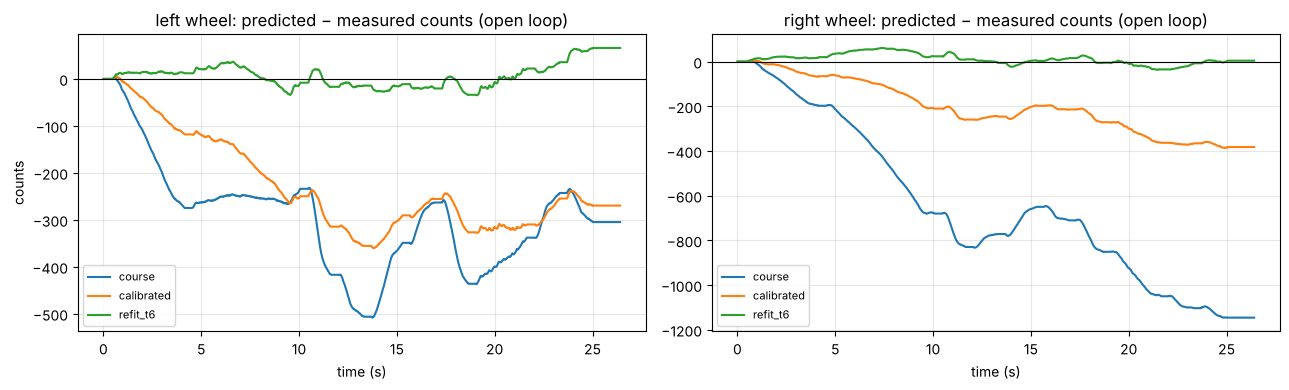

,model,k_left,k_right,deadband,rms_count_error
0,course,1.250,1.250,0.0,569.903
1,calibrated,3.992,3.117,14.9,243.762
2,refit_t6,4.567,3.370,14.1,26.459


In [9]:
def open_loop_counts(model, d):
    bot = twin.Robot(model)
    cl, cr = [0.0], [0.0]
    t, uL, uR = d.time_ms.values, d.left_pwm.values, d.right_pwm.values
    for i in range(1, len(t)):
        bot.pwm_l, bot.pwm_r = uL[i - 1], uR[i - 1]
        for _ in range(int(t[i] - t[i - 1])):
            bot.step_1ms()
        cl.append(bot.nl); cr.append(bot.nr)
    return np.array(cl), np.array(cr)

if real:
    d = list(real.values())[0]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
    rows = []
    for name, m in twin.MODELS.items():
        cl, cr = open_loop_counts(m, d)
        ax[0].plot(d.time_ms / 1000, cl - d.left_counts, label=name)
        ax[1].plot(d.time_ms / 1000, cr - d.right_counts, label=name)
        rows.append({"model": name, "k_left": m.k_left, "k_right": m.k_right, "deadband": m.deadband,
                     "rms_count_error": float(np.sqrt(np.mean(np.r_[cl - d.left_counts, cr - d.right_counts] ** 2)))})
    for a, side in zip(ax, ("left", "right")):
        a.axhline(0, color="k", lw=0.8); a.grid(alpha=0.3); a.legend(fontsize=8)
        a.set_title(f"{side} wheel: predicted − measured counts (open loop)"); a.set_xlabel("time (s)")
    ax[0].set_ylabel("counts")
    plt.tight_layout(); plt.savefig(f"{BASE}/analysis/open_loop_replay.png", dpi=120, bbox_inches="tight"); plt.show()
    display(pd.DataFrame(rows).round(3))
else:
    print("needs a real run")

## 9. Findings (real run `path_t6`, wooden floor, new batteries)

* **The controller and the encoder behaviour are reproduced closely.** Per segment, the real wheel counts match the
  calibrated twin within about 5 counts (≈ 1.4 mm), and the real odometry's small sideways shift on each straight
  (left wheel leads at the start, −0.7 to −3.2 mm per straight) appears in the calibrated twin (right-wheel delay) but not in
  the course twin.
* **Divergence starts with speed, not geometry.** Aligned by time, the course twin is > 5 mm away after about 1 s and
  the calibrated twin after about 1.5 s; aligned by progress (same fraction of each segment) both stay within
  a few millimetres. The calibrated twin needed 11–33 % (mean ≈ 20 %) longer per segment than the real robot: motor gain depends on battery
  voltage and surface, which the model does not represent.
* **Updating the twin works:** re-fitting only the two motor gains on this run (k_left 3.99 → 4.57,
  k_right 3.12 → 3.37 mm/s per PWM) cuts the open-loop count error from ≈ 244 to ≈ 26 counts rms and the time-aligned
  mean position difference from ≈ 50 mm to ≈ 6 mm (total time 26.7 s vs 26.4 s). This was fitted and judged on the same
  run, so it must be validated on another run.
* **Geometry (B) is the largest physical risk:** the course twin's B = 90 mm makes every commanded 90° turn about 82°.
  The real robot's own odometry cannot show this (it uses the same B as its controller), so physical checkpoints
  (`CHECKPOINT_PAUSE_MS = 3000`) are needed to test it.
* Limits: one complete real run; positions along the path come from the robot's encoder odometry, not from an
  external measurement (the video was hand-held and is not used for measurement).